# 2 · The reference: measuring the flux by eddy covariance

Turbulent eddies carry heat upward when rising air ($w' > 0$) is on average warmer ($\theta' > 0$) than sinking
air. The sensible heat flux is this covariance, scaled by the heat capacity of air:

$$H_\mathrm{S} = \rho\, c_p\, \overline{w'\theta'}$$

This chapter computes it for **one 5 km segment, step by step**, and arrives at the value stored in the data file.

In [1]:
import sys, warnings
from pathlib import Path
import numpy as np, pandas as pd, xarray as xr
import matplotlib.pyplot as plt
warnings.filterwarnings("ignore")
REPO = Path("..").resolve(); sys.path.insert(0, str(REPO))
plt.rcParams.update({"figure.dpi": 110, "figure.constrained_layout.use": True, "axes.grid": True, "grid.alpha": 0.3, "font.size": 10})

AR  = REPO / "data/observations/ar"
FIG = xr.open_dataset(REPO / "data/model_output/sensitivity_figure_data.nc")      # all flux estimates, 91 segments
SEG = xr.open_dataset(AR / "analysis_ready_polar6_turbulent_fluxes_latest_5km.nc").sel(start_time=FIG.start_time.values)
EC  = FIG["H_obs_ec"].values

from fluxpy.meteorology import add_theta
from fluxpy.flux_processing import band_covariance, get_cov
from fluxpy.util import CP

TB = xr.open_dataset(REPO / "data/observations/processed/t-bird_unified/noseboom_unified.nc").sortby("time")
i = int(np.nanargmax(EC))                                   # the segment with the largest upward flux
t0, t1 = SEG.start_time.values[i], SEG.end_time.values[i]
seg = add_theta(TB.sel(time=slice(t0, t1))).dropna("time", how="any")
print(f"segment {pd.Timestamp(t0):%d %b %Y %H:%M:%S} UTC: {seg.time.size} samples = {seg.time.size / 100:.0f} s at 100 Hz, "
      f"height {float(seg.h.mean()):.0f} m, airspeed {float(seg.tas.mean()):.0f} m/s")

segment 15 Apr 2024 10:18:10 UTC: 8500 samples = 85 s at 100 Hz, height 25 m, airspeed 58 m/s


## Step 1 — the raw signals

Vertical wind $w$ and potential temperature $\theta$. A linear trend is removed from both; what remains are the
turbulent fluctuations $w'$ and $\theta'$.

plain covariance of the detrended series: 0.0134 K m/s


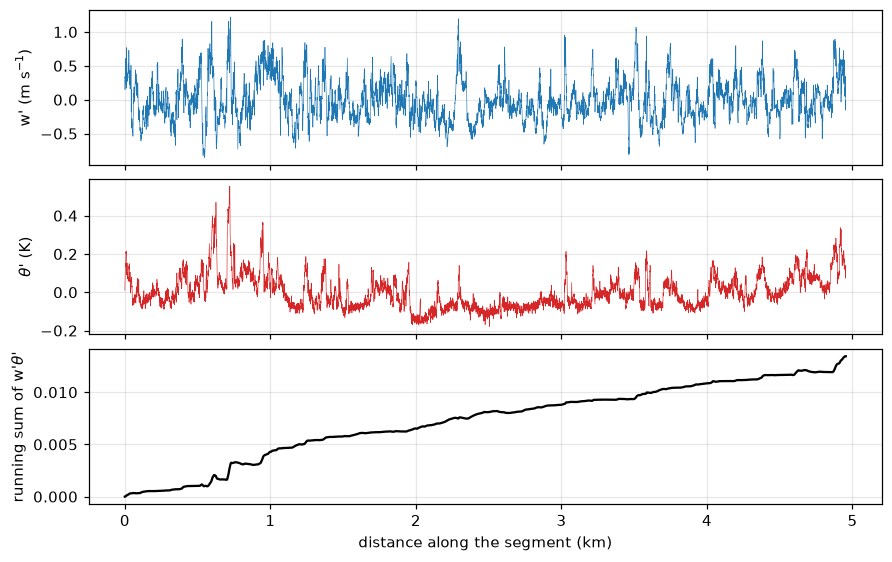

In [2]:
from scipy.signal import detrend
w, th = detrend(seg.w.values), detrend(seg.theta.values)
x_km = np.arange(w.size) / 100 * float(seg.tas.mean()) / 1000
fig, axs = plt.subplots(3, 1, figsize=(8, 5), sharex=True)
axs[0].plot(x_km, w, lw=0.4, color="C0"); axs[0].set_ylabel("w' (m s$^{-1}$)")
axs[1].plot(x_km, th, lw=0.4, color="C3"); axs[1].set_ylabel(r"$\theta$' (K)")
axs[2].plot(x_km, np.cumsum(w * th) / w.size, color="k"); axs[2].set_ylabel(r"running sum of w'$\theta$'"); axs[2].set_xlabel("distance along the segment (km)")
print(f"plain covariance of the detrended series: {np.mean(w * th):.4f} K m/s")

## Step 2 — which eddy sizes carry the flux?

The cospectrum splits the covariance by frequency. At 61 m s⁻¹ airspeed a frequency $f$ corresponds to an eddy of
length $61\,\mathrm{m\,s^{-1}}/f$. The paper integrates the cospectrum between **0.1 and 20 Hz** (eddies of about 3 to 610 m):
slower variations are mesoscale changes along the track rather than turbulence, faster ones are instrument noise.

The shaded band below is what enters the flux.

covariance inside 0.1-20 Hz: 0.0093 K m/s = 69 % of the total covariance of this segment


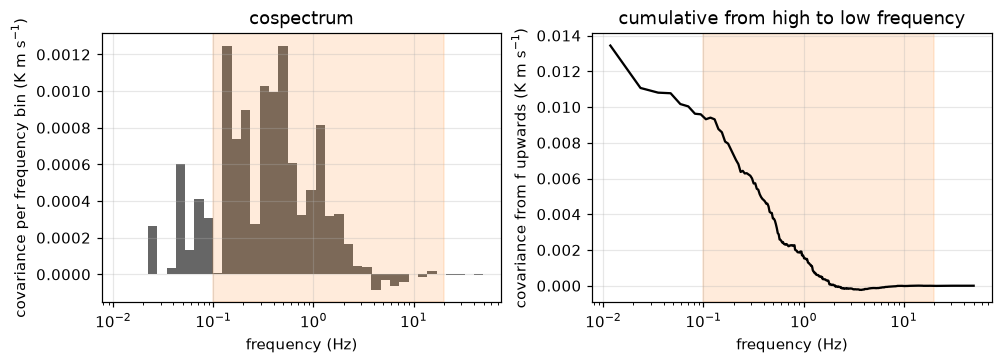

In [3]:
n, fs = w.size, 100.0
f = np.fft.rfftfreq(n, 1 / fs)
co = 2 * np.real(np.fft.rfft(w) * np.conj(np.fft.rfft(th))) / n**2       # one-sided cospectrum; sums to the covariance
edges = np.logspace(np.log10(f[1]), np.log10(50), 40); mid = np.sqrt(edges[:-1] * edges[1:])
binned = np.array([co[(f >= a) & (f < b)].sum() for a, b in zip(edges[:-1], edges[1:])])

fig, axs = plt.subplots(1, 2, figsize=(9, 3.2))
axs[0].bar(mid, binned, width=np.diff(edges), color="0.4"); axs[0].set_xscale("log")
axs[0].set_ylabel("covariance per frequency bin (K m s$^{-1}$)"); axs[0].set_title("cospectrum")
axs[1].plot(f[1:], np.cumsum(co[1:][::-1])[::-1], color="k"); axs[1].set_xscale("log")
axs[1].set_ylabel("covariance from f upwards (K m s$^{-1}$)"); axs[1].set_title("cumulative from high to low frequency")
for ax in axs:
    ax.axvspan(0.1, 20, color="C1", alpha=0.15); ax.set_xlabel("frequency (Hz)")
in_band = band_covariance(w, th, fs, 0.1, 20.0)
print(f"covariance inside 0.1-20 Hz: {in_band:.4f} K m/s = {in_band / np.mean(w * th) * 100:.0f} % of the total covariance of this segment")

## Step 3 — from covariance to W m⁻²

In [4]:
rho = float((seg.p * 100 / (287.05 * (seg["T"] + 273.15))).mean())        # dry-air density from p (hPa) and T (degC)
H_by_hand = rho * CP * in_band
_, H_fluxpy = get_cov(seg.copy(), "theta", heat_flux=True, time_dim="time", highpass=False)
print(f"rho = {rho:.2f} kg m-3, c_p = {CP:.0f} J kg-1 K-1")
print(f"H by hand         : {H_by_hand:6.2f} W m-2")
print(f"H from fluxpy     : {float(H_fluxpy):6.2f} W m-2")
print(f"H in the data file: {EC[i]:6.2f} W m-2")

rho = 1.40 kg m-3, c_p = 1004 J kg-1 K-1
H by hand         :  13.14 W m-2
H from fluxpy     :  13.15 W m-2
H in the data file:  13.15 W m-2


## Step 4 — how good is this number? (Appendix A)

Two questions have to be kept apart.

**Is the measurement sound?** Turbulence must be resolved: the power spectrum of $w$ has to fall off with a slope near
$-5/3$ (inertial subrange), $|s_w + 5/3| \le 0.4$. This is a pass/fail check of the *instrument and the processing*.

**How precisely is the flux known?** A covariance from 85 s of data has a random error, because only a limited number of
eddies were sampled. It is estimated from the data themselves (Finkelstein and Sims, 2001). A flux larger than 1.96 times its
random error is *detectable*, i.e. distinguishable from zero.

Fluxes below the detection limit are **kept**. Over compact sea ice "no measurable flux" is the typical, physically correct
result; throwing these segments away would leave only the large fluxes and bias the reference. For the same reason the paper
does not use criteria that are ratios to the flux (such as signal-to-noise ratios): they fail for small fluxes and pass for
large ones, whatever the quality of the measurement.

In [5]:
from fluxpy.qc import qc_leg, turbulence_resolved
from fluxpy.flux_processing import band_covariance_random_error, C_P
slope = qc_leg(w=seg.w.values, theta=seg.theta.values, u=seg.u.values, v=seg.v.values, fs=100.0)["slope_w"]
sigma = rho * C_P * band_covariance_random_error(w, th, fs)
print(f"this segment: spectral slope of w = {slope:.2f} -> turbulence resolved: {turbulence_resolved(slope)}")
print(f"              flux {float(H_fluxpy):.1f} +- {sigma:.1f} W m-2 (random error) -> detectable: {abs(float(H_fluxpy)) > 1.96 * sigma}")
det = FIG.ec_detectable.values == 1
print(f"\nall {det.size} segments: {int(SEG.turbulence_resolved.sum())} pass the integrity check; "
      f"median random error {np.median(FIG.sigma_random_ec.values):.1f} W m-2; {det.sum()} fluxes are detectable")
days = pd.to_datetime(FIG.start_time.values).strftime("%d %b")
print("detectable per day:", {d: f"{det[days == d].sum()}/{(days == d).sum()}" for d in pd.unique(days)})

this segment: spectral slope of w = -1.55 -> turbulence resolved: True
              flux 13.1 +- 2.0 W m-2 (random error) -> detectable: True

all 91 segments: 91 pass the integrity check; median random error 0.7 W m-2; 47 fluxes are detectable
detectable per day: {'13 Apr': '8/18', '15 Apr': '22/22', '17 Apr': '13/26', '23 Apr': '4/25'}


15 April, the day with open leads and the largest fluxes, is fully detectable; on the days over compact ice or with weak
temperature contrast most fluxes are statistically zero. That is a property of the Arctic surface, not a defect of the data —
and it is the reason why the correlations in Chapter 4 cannot be high for *any* estimate.

## Is 5 km long enough? (Fig. 2)

A short window might miss the larger eddies; a long one blurs leads and ice together. The experiment cuts each of the six
low-level legs into sub-windows of different length and compares their mean flux with the flux of the complete leg
(`scripts/ec_window_length.py`).

at 5 km: flux ratio 1.0, random error 0.8 W m-2, detectable fluxes 48 %


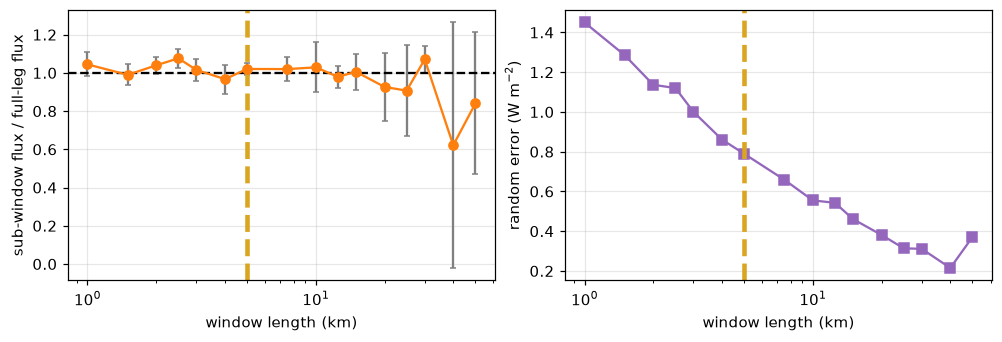

In [6]:
wl = pd.read_csv(AR / "ec_leg_length_sensitivity/ec_sensitivity_summary.csv").query("length_km >= 1 and label != 'full leg'")
fig, axs = plt.subplots(1, 2, figsize=(9, 3))
axs[0].errorbar(wl.length_km, wl.ratio_mean, wl.ratio_std, fmt="o-", color="C1", ecolor="0.5", capsize=2)
axs[0].axhline(1, color="k", ls="--"); axs[0].set_ylabel("sub-window flux / full-leg flux")
axs[1].plot(wl.length_km, wl.random_error_median, "s-", color="C4"); axs[1].set_ylabel("random error (W m$^{-2}$)")
for ax in axs:
    ax.set_xscale("log"); ax.axvline(5, color="goldenrod", lw=3, ls="--"); ax.set_xlabel("window length (km)")
r5 = wl[wl.length_km == 5].iloc[0]
print(f"at 5 km: flux ratio {r5.ratio_mean:.1f}, random error {r5.random_error_median:.1f} W m-2, detectable fluxes {r5.fraction_detectable * 100:.0f} %")

## How uncertain is one EC flux?

Two contributions, added in quadrature: the **random** error from Step 4 and the **instrument** error (5 % from the flow
calibration of the five-hole probe). An independent, purely empirical check of the random error is the **placement** spread —
what happens to the flux when the 5 km window is shifted along the leg in 0.05 km steps (`scripts/ec_segment_placement.py`).
It is not added, because it measures the same thing; it is there to show that the random error has the right size.

In [7]:
from fluxpy.uncertainty import uncertainty_budget
U = uncertainty_budget(FIG)
pd.DataFrame({k.replace("ec_", ""): [np.nanmedian(U[k]), np.nanpercentile(U[k], 25), np.nanpercentile(U[k], 75)]
              for k in ("ec_random", "ec_instrument", "ec_total", "ec_placement")},
             index=["median (W m-2)", "25th percentile", "75th percentile"]).round(1)

,random,instrument,total,placement
median (W m-2),0.7,0.1,0.8,0.9
25th percentile,0.2,0.0,0.2,0.2
75th percentile,1.5,0.2,1.5,1.3


**Take-away.** The reference flux is a band-limited covariance that can be recomputed from the 100 Hz data in a few lines.
Its uncertainty is dominated by the limited number of eddies in 5 km — confirmed by shifting the window along the track — not by the instrument.